# DATA 266 Lab 2 - Part 2: Fine-tuning Stable Diffusion 1.5 for Naruto-style images

Data: `lambdalabs/naruto-blip-captions` (1,221 images with BLIP captions). Base model: `stable-diffusion-v1-5`.
Two runs with the **same data, steps, batch size and learning rate**: (1) LoRA rank 4, (2) LoRA rank 32.
Evaluation against the **base model**: KID (in-domain vs test images), CLIP score, LPIPS diversity between seeds,
blinded human comparison, GPU-hours and peak memory; safety: license, NSFW filter, memorization check.

Sections: 0 setup | 1 data (2.1) | 2 training (2.2) | 3 generation (2.3) | 4 evaluation (2.4) | 5 human evaluation |
6 failure modes | 7 safety (C4) | 8 Hugging Face upload | 9 results table.

In [1]:
# Cell 1 - run information (required)
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
try:
    commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
    text=True).stdout.strip()
except OSError:  # git not installed
    commit = ""
commit = commit or "40d4aa4"  # copy without .git: commit the notebook was generated from (tag p2-v1.0)
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': '40d4aa4', 'python': '3.13.3', 'torch': '2.11.0+cu128', 'gpu': 'NVIDIA GeForce RTX 4090', 'seed': 266}


## 0. Setup

In [2]:
import importlib.metadata as md, subprocess, sys
PINS = {'diffusers': '0.43.0', 'peft': '0.21.2', 'transformers': '5.22.2', 'accelerate': '1.15.0', 'datasets': '5.2.0',
        'torchmetrics': '1.9.0', 'torch-fidelity': '0.4.0', 'lpips': '0.1.4'}
def _ver(p):
    try:
        return md.version(p)
    except md.PackageNotFoundError:
        return None
todo = [f"{p}=={v}" for p, v in PINS.items() if _ver(p) != v]
if todo:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo], check=True)
print({p: _ver(p) for p in PINS})

{'diffusers': '0.43.0', 'peft': '0.21.2', 'transformers': '5.22.2', 'accelerate': '1.15.0', 'datasets': '5.2.0', 'torchmetrics': '1.9.0', 'torch-fidelity': '0.4.0', 'lpips': '0.1.4'}


In [3]:
import os; os.makedirs('p2', exist_ok=True); os.makedirs('eval_p2', exist_ok=True)

In [4]:
%%writefile p2/__init__.py
"""DATA 266 Lab 2 Part 2 - fine-tuning Stable Diffusion 1.5 with LoRA."""

Overwriting p2/__init__.py


In [5]:
%%writefile p2/config.py
"""Settings for Part 2 (fine-tuning Stable Diffusion 1.5 on Naruto BLIP captions)."""
from __future__ import annotations

import os
from dataclasses import dataclass, field

SEED = 266


def _env(name, default):
    v = os.environ.get(name)
    if v is None:
        return default
    if isinstance(default, bool):
        return v.strip().lower() in {"1", "true", "yes"}
    return type(default)(v)


@dataclass
class P2Config:
    dataset: str = field(default_factory=lambda: _env("P2_DATASET", "lambdalabs/naruto-blip-captions"))
    base_model: str = field(default_factory=lambda: _env("P2_BASE", "stable-diffusion-v1-5/stable-diffusion-v1-5"))
    work_dir: str = field(default_factory=lambda: _env("P2_WORK", "artifacts_p2"))
    resolution: int = field(default_factory=lambda: _env("P2_RES", 512))  # smaller only for CPU tests
    test_fraction: float = 0.10
    seed: int = SEED
    min_side: int = 128  # images smaller than this count as corrupted / unusable
    dup_hamming: int = 4  # perceptual-hash distance at or below which two images are near-duplicates

    # training (both runs share data, steps, batch size and learning rate; only the adapter differs)
    max_steps: int = field(default_factory=lambda: _env("P2_STEPS", 1500))
    batch_size: int = field(default_factory=lambda: _env("P2_BATCH", 4))
    lr: float = field(default_factory=lambda: _env("P2_LR", 1e-4))
    warmup_steps: int = 100
    snr_gamma: float = 5.0  # min-SNR loss weighting
    grad_checkpointing: bool = True
    runs: tuple = (("run1_lora_r4", 4), ("run2_lora_r32", 32))  # (name, LoRA rank); alpha = rank

    # generation (same sampler settings for every model)
    steps: int = 30
    guidance: float = 7.5
    gen_seeds: tuple = (0, 1)

    # Hugging Face (optional; needs HF_TOKEN)
    hf_user: str = field(default_factory=lambda: _env("HF_USER", ""))
    hf_model_prefix: str = field(default_factory=lambda: _env("HF_MODEL_PREFIX", "sd15-naruto"))
    hf_images_repo: str = field(default_factory=lambda: _env("HF_IMAGES_REPO", "lab2-p2-generated-images"))

Overwriting p2/config.py


In [6]:
%%writefile p2/data.py
"""Task 2.1 - data preparation: load, remove corrupted and duplicate images, split 90/10 (seed 266), resize.

Duplicates: exact duplicates (same pixels after decoding) and near-duplicates (64-bit difference hash within
`dup_hamming` bits). Of each duplicate group the first image is kept.
"""
from __future__ import annotations

import hashlib
import io
import json
import os
from dataclasses import dataclass, field

import numpy as np
from PIL import Image, ImageOps

from .config import P2Config


@dataclass
class CleanReport:
    total: int = 0
    corrupted: list = field(default_factory=list)  # (index, reason)
    exact_duplicates: list = field(default_factory=list)  # (index, kept_index)
    near_duplicates: list = field(default_factory=list)  # (index, kept_index, hamming)
    kept: list = field(default_factory=list)

    def summary(self) -> dict:
        return {"total": self.total, "corrupted_removed": len(self.corrupted),
                "exact_duplicates_removed": len(self.exact_duplicates),
                "near_duplicates_removed": len(self.near_duplicates), "kept": len(self.kept)}


def dhash(img: Image.Image, size: int = 8) -> int:
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.LANCZOS), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def _decode(x) -> Image.Image:
    if isinstance(x, Image.Image):
        x.load()
        return x
    if isinstance(x, dict) and x.get("bytes") is not None:
        x = x["bytes"]
    if isinstance(x, (bytes, bytearray)):
        im = Image.open(io.BytesIO(x))
        im.verify()  # structural check
        im = Image.open(io.BytesIO(x))
        im.load()
        return im
    raise ValueError(f"unsupported image value {type(x)}")


def clean(images, captions, cfg: P2Config, log=print) -> CleanReport:
    """images: iterable of PIL images / raw bytes; returns which indices to keep and why others were removed."""
    rep = CleanReport()
    seen_md5, hashes = {}, []
    for i, (raw, cap) in enumerate(zip(images, captions)):
        rep.total += 1
        try:
            im = _decode(raw)
            im = ImageOps.exif_transpose(im).convert("RGB")
        except Exception as e:  # cannot be decoded
            rep.corrupted.append((i, f"undecodable: {type(e).__name__}"))
            continue
        if min(im.size) < cfg.min_side:
            rep.corrupted.append((i, f"too small {im.size}"))
            continue
        arr = np.asarray(im)
        if arr.std() < 2:
            rep.corrupted.append((i, "blank / single colour"))
            continue
        if not str(cap or "").strip():
            rep.corrupted.append((i, "empty caption"))
            continue
        md5 = hashlib.md5(arr.tobytes()).hexdigest()
        if md5 in seen_md5:
            rep.exact_duplicates.append((i, seen_md5[md5]))
            continue
        seen_md5[md5] = i
        h = dhash(im)
        near = None
        for j, hj in hashes:
            d = bin(h ^ hj).count("1")
            if d <= cfg.dup_hamming:
                near = (j, d)
                break
        if near:
            rep.near_duplicates.append((i, near[0], near[1]))
            continue
        hashes.append((i, h))
        rep.kept.append(i)
    log(f"[data] {rep.summary()}")
    return rep


def split(kept: list[int], cfg: P2Config) -> tuple[list[int], list[int]]:
    """90/10 split of the cleaned indices with seed 266 (test images are used only for evaluation)."""
    rng = np.random.default_rng(cfg.seed)
    order = rng.permutation(len(kept))
    n_test = int(round(cfg.test_fraction * len(kept)))
    test = sorted(kept[k] for k in order[:n_test])
    train = sorted(kept[k] for k in order[n_test:])
    return train, test


def to_square(im: Image.Image, size: int) -> Image.Image:
    """Resize the short side to `size` and centre-crop (the model's 512x512 resolution)."""
    im = im.convert("RGB")
    w, h = im.size
    s = size / min(w, h)
    im = im.resize((max(size, round(w * s)), max(size, round(h * s))), Image.BICUBIC)
    w, h = im.size
    l, t = (w - size) // 2, (h - size) // 2
    return im.crop((l, t, l + size, t + size))


def prepare(cfg: P2Config, log=print) -> dict:
    """Load the dataset, clean, split, resize and write <work>/data/{train,test}/*.png + captions.jsonl."""
    from datasets import load_dataset
    ds = load_dataset(cfg.dataset, split="train")
    ds_raw = ds.cast_column("image", ds.features["image"].__class__(decode=False))
    caps = ds["text"]
    rep = clean((r["image"] for r in ds_raw), caps, cfg, log)
    train, test = split(rep.kept, cfg)
    out = {}
    for name, idx in (("train", train), ("test", test)):
        d = os.path.join(cfg.work_dir, "data", name)
        os.makedirs(d, exist_ok=True)
        rows = []
        for i in idx:
            im = to_square(_decode(ds_raw[i]["image"]), cfg.resolution)
            fn = f"{i:05d}.png"
            im.save(os.path.join(d, fn))
            rows.append({"file": fn, "index": i, "text": caps[i]})
        with open(os.path.join(d, "captions.jsonl"), "w", encoding="utf-8") as fh:
            for r in rows:
                fh.write(json.dumps(r) + "\n")
        out[name] = rows
    out["report"] = rep
    log(f"[data] train={len(train)} test={len(test)} written to {os.path.join(cfg.work_dir, 'data')}")
    return out


def describe(rows: list[dict]) -> dict:
    caps = [r["text"] for r in rows]
    words = [len(c.split()) for c in caps]
    first = {}
    for c in caps:
        k = " ".join(c.split()[:2])
        first[k] = first.get(k, 0) + 1
    return {"n": len(rows), "caption_words_mean": float(np.mean(words)), "caption_words_min": int(np.min(words)),
            "caption_words_max": int(np.max(words)),
            "most_common_openings": sorted(first.items(), key=lambda x: -x[1])[:8]}


def load_split(cfg: P2Config, name: str) -> list[dict]:
    d = os.path.join(cfg.work_dir, "data", name)
    with open(os.path.join(d, "captions.jsonl"), encoding="utf-8") as fh:
        rows = [json.loads(l) for l in fh]
    for r in rows:
        r["path"] = os.path.join(d, r["file"])
    return rows

Overwriting p2/data.py


In [7]:
%%writefile p2/evaluate.py
"""Task 2.4 - evaluation of the base model and both fine-tuning runs.

  primary    KID (in-domain generations vs test images; noisy with 20 images) and CLIP score (prompt vs image)
  secondary  diversity: LPIPS distance between the two seeds of each prompt
  human      blinded pairs (final run vs base, left/right randomised), >= 3 raters -> win rate
  efficiency GPU-hours per training run and peak GPU memory (from train_stats.json)
  safety     NSFW flags from the SD safety checker; memorization check (CLIP image similarity to training images)
"""
from __future__ import annotations

import csv
import os
import random

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw, ImageFont

from .config import P2Config

CLIP_ID = "openai/clip-vit-large-patch14"


def _dev():
    return "cuda" if torch.cuda.is_available() else "cpu"


def _u8(paths, size=299):
    arr = [np.asarray(Image.open(p).convert("RGB").resize((size, size), Image.BICUBIC)) for p in paths]
    return torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2).contiguous()


def kid(gen_paths: list[str], real_paths: list[str]) -> tuple[float, float]:
    from torchmetrics.image.kid import KernelInceptionDistance
    sub = min(len(gen_paths), len(real_paths), 50)
    m = KernelInceptionDistance(subset_size=sub, subsets=50).to(_dev())
    for i in range(0, len(real_paths), 32):
        m.update(_u8(real_paths[i:i + 32]).to(_dev()), real=True)
    for i in range(0, len(gen_paths), 32):
        m.update(_u8(gen_paths[i:i + 32]).to(_dev()), real=False)
    mean, std = m.compute()
    return float(mean), float(std)


class Clip:
    def __init__(self, model_id=CLIP_ID):
        from transformers import CLIPModel, CLIPProcessor
        self.model = CLIPModel.from_pretrained(model_id).to(_dev()).eval()
        self.proc = CLIPProcessor.from_pretrained(model_id)

    @torch.inference_mode()
    def image_emb(self, paths, bs=32):
        out = []
        for i in range(0, len(paths), bs):
            ims = [Image.open(p).convert("RGB") for p in paths[i:i + bs]]
            x = self.proc(images=ims, return_tensors="pt").to(_dev())
            e = self.model.get_image_features(**x)
            e = e if isinstance(e, torch.Tensor) else e.pooler_output
            out.append(torch.nn.functional.normalize(e.float(), dim=-1).cpu())
        return torch.cat(out)

    @torch.inference_mode()
    def text_emb(self, texts):
        x = self.proc(text=texts, return_tensors="pt", padding=True, truncation=True, max_length=77).to(_dev())
        e = self.model.get_text_features(**x)
        e = e if isinstance(e, torch.Tensor) else e.pooler_output
        return torch.nn.functional.normalize(e.float(), dim=-1).cpu()

    def score(self, paths, texts) -> list[float]:
        """CLIP score = 100 * max(cos(image, text), 0) (as in torchmetrics' CLIPScore)."""
        ie, te = self.image_emb(paths), self.text_emb(texts)
        return [float(100 * max(0.0, (a * b).sum())) for a, b in zip(ie, te)]


def lpips_pairs(rows: list[dict]) -> pd.DataFrame:
    """LPIPS (AlexNet) between the seed-0 and seed-1 image of every prompt and model (higher = more diverse)."""
    import lpips
    # P2_LPIPS_RANDOM=1 only for offline CPU tests (the backbone weights come from download.pytorch.org)
    rand = os.environ.get("P2_LPIPS_RANDOM") == "1"
    net = lpips.LPIPS(net="alex", verbose=False, pnet_rand=rand).to(_dev()).eval()
    df = pd.DataFrame(rows)
    if "nsfw_filtered" in df:
        df = df[~df.nsfw_filtered]
    out = []
    for (m, pid), g in df.groupby(["model", "prompt_id"]):
        if len(g) < 2:
            continue
        a, b = [torch.from_numpy(np.asarray(Image.open(p).convert("RGB").resize((256, 256)), dtype=np.float32) / 127.5 - 1)
                .permute(2, 0, 1)[None].to(_dev()) for p in g.sort_values("seed")["path"][:2]]
        with torch.no_grad():
            d = float(net(a, b).item())
        out.append({"model": m, "prompt_id": pid, "kind": g["kind"].iloc[0], "lpips": d})
    return pd.DataFrame(out)


def grid(rows: list[dict], prompt_ids: list[str], models: list[str], path: str, seed: int = 0, size: int = 256):
    df = pd.DataFrame(rows)
    pad, head = 6, 28
    W = len(models) * (size + pad) + 260
    H = len(prompt_ids) * (size + pad) + head
    canvas = Image.new("RGB", (W, H), "white")
    d = ImageDraw.Draw(canvas)
    try:
        f = ImageFont.truetype("DejaVuSans.ttf", 13)
    except OSError:
        f = ImageFont.load_default()
    for j, m in enumerate(models):
        d.text((260 + j * (size + pad) + 4, 6), m, fill="black", font=f)
    for i, pid in enumerate(prompt_ids):
        y = head + i * (size + pad)
        sub = df[(df.prompt_id == pid) & (df.seed == seed)]
        prompt = sub["prompt"].iloc[0] if len(sub) else pid
        words, line, lines = prompt.split(), "", []
        for w in words:
            if len(line) + len(w) > 32:
                lines.append(line); line = ""
            line += w + " "
        lines.append(line)
        d.text((4, y + 4), f"{pid}\n" + "\n".join(lines), fill="black", font=f)
        for j, m in enumerate(models):
            r = sub[sub.model == m]
            if len(r):
                canvas.paste(Image.open(r["path"].iloc[0]).convert("RGB").resize((size, size)), (260 + j * (size + pad), y))
    canvas.save(path)
    return path


def memorization(clip: Clip, gen_paths: list[str], train_paths: list[str], k: int = 3) -> list[dict]:
    """For each generated image, the most similar training image (CLIP image cosine); returns the k closest pairs."""
    tr = clip.image_emb(train_paths)
    ge = clip.image_emb(gen_paths)
    sim = ge @ tr.T
    best = sim.max(dim=1)
    rows = [{"generated": g, "nearest_train": train_paths[int(j)], "cosine": float(v)}
            for g, v, j in zip(gen_paths, best.values, best.indices)]
    return sorted(rows, key=lambda r: -r["cosine"])[:k], rows


def pair_image(a: str, b: str, path: str, size=384):
    c = Image.new("RGB", (2 * size + 30, size + 40), "white")
    c.paste(Image.open(a).convert("RGB").resize((size, size)), (0, 40))
    c.paste(Image.open(b).convert("RGB").resize((size, size)), (size + 30, 40))
    d = ImageDraw.Draw(c)
    d.text((size // 2 - 5, 10), "A", fill="black")
    d.text((size + 30 + size // 2 - 5, 10), "B", fill="black")
    c.save(path)


def human_eval_sheets(rows: list[dict], final: str, base: str, out_dir: str, n: int = 25, seed: int = 266,
                      raters=("rater1", "rater2", "rater3")) -> tuple[str, str]:
    """Blinded pairs (final vs base, left/right randomised). The key is kept in a separate file."""
    os.makedirs(out_dir, exist_ok=True)
    sheet, key = os.path.join(out_dir, "p2_human_eval.csv"), os.path.join(out_dir, "p2_human_eval_KEY.csv")
    if os.path.isfile(sheet):  # keep a sheet that already has ratings; rebuild an empty one (images may have changed)
        old = pd.read_csv(sheet, dtype=str, keep_default_na=False)
        if any((old[c].str.strip() != "").any() for c in old.columns if c.startswith("rater")):
            return sheet, key
    df = pd.DataFrame(rows)
    if "nsfw_filtered" in df:
        ok = df[~df.nsfw_filtered].groupby(["prompt_id", "seed"]).model.nunique()
        keep = set(ok[ok == df.model.nunique()].index)  # pairs where neither image was filtered
        df = df[[(p, s_) in keep for p, s_ in zip(df.prompt_id, df.seed)]]
    combos = sorted(set(zip(df.prompt_id, df.seed)))
    rng = random.Random(seed)
    pick = rng.sample(combos, min(n, len(combos)))
    srows, krows = [], []
    for k, (pid, s) in enumerate(pick, 1):
        f = df[(df.model == final) & (df.prompt_id == pid) & (df.seed == s)].iloc[0]
        b = df[(df.model == base) & (df.prompt_id == pid) & (df.seed == s)].iloc[0]
        final_left = rng.random() < 0.5
        left, right = (f, b) if final_left else (b, f)
        img = os.path.join(out_dir, f"pair_{k:02d}.png")
        pair_image(left["path"], right["path"], img)
        r = {"pair": k, "image": os.path.basename(img), "prompt": f["prompt"]}
        for rt in raters:
            r[f"{rt}_style"] = ""   # A or B: which image is more in the Naruto domain style
            r[f"{rt}_prompt"] = ""  # A or B: which image matches the prompt better
        srows.append(r)
        krows.append({"pair": k, "final_is": "A" if final_left else "B", "prompt_id": pid, "seed": s})
    pd.DataFrame(srows).to_csv(sheet, index=False)
    pd.DataFrame(krows).to_csv(key, index=False)
    return sheet, key


def human_eval_stats(sheet: str, key: str) -> dict | None:
    if not (os.path.isfile(sheet) and os.path.isfile(key)):
        return None
    s = pd.read_csv(sheet, dtype=str, keep_default_na=False)
    k = pd.read_csv(key, dtype=str, keep_default_na=False).set_index("pair")
    out = {}
    for crit in ("style", "prompt"):
        cols = [c for c in s.columns if c.endswith(f"_{crit}")]
        wins = total = 0
        per_rater = {}
        for c in cols:
            v = s[c].str.strip().str.upper()
            ok = v.isin(["A", "B"])
            fin = s.loc[ok, "pair"].map(lambda p: k.loc[str(p), "final_is"])
            w = int((v[ok] == fin).sum())
            per_rater[c.rsplit("_", 1)[0]] = f"{w}/{int(ok.sum())}"
            wins += w
            total += int(ok.sum())
        if total:
            out[f"win_rate_{crit}"] = round(wins / total, 3)
            out[f"votes_{crit}"] = total
            out[f"per_rater_{crit}"] = per_rater
    return out or None


def summary_table(gen_rows, test_paths, train_stats: dict, lp: pd.DataFrame) -> pd.DataFrame:
    df = pd.DataFrame(gen_rows)
    rows = []
    for m in df.model.unique():
        d_all = df[df.model == m]
        d = d_all[~d_all.nsfw_filtered]  # metrics only on images that passed the NSFW filter
        lp_m = lp[(lp.model == m) & lp.prompt_id.isin(d.prompt_id)]
        ind = d[d.kind == "in_domain"]
        k_mean, k_std = kid(list(ind.path), test_paths)
        ts = train_stats.get(m, {})
        rows.append({
            "model": m,
            "KID in-domain (x1e3, lower=better)": f"{1e3 * k_mean:.2f} +- {1e3 * k_std:.2f}",
            "CLIP score all": round(float(d.clip_score.mean()), 2),
            "CLIP in-domain": round(float(ind.clip_score.mean()), 2),
            "CLIP out-of-domain": round(float(d[d.kind == "out_of_domain"].clip_score.mean()), 2),
            "CLIP compositional": round(float(d[d.kind == "compositional"].clip_score.mean()), 2),
            "LPIPS diversity": round(float(lp_m.lpips.mean()), 3),
            "images used / 40": f"{len(d)}/{len(d_all)}",
            "NSFW filtered (classifier)": int(d_all.nsfw_filtered.sum()),
            "SD checker would flag": int(d_all.sd_checker_flag.fillna(False).astype(bool).sum()),
            "GPU-hours (training)": ts.get("gpu_hours", "-"),
            "peak GPU memory GB (training)": ts.get("peak_gpu_memory_gb", "-"),
        })
    return pd.DataFrame(rows)

Overwriting p2/evaluate.py


In [8]:
%%writefile p2/generate.py
"""Task 2.3 - generate 20 prompts x 2 seeds for the base model and both runs (same sampler settings).

NSFW filter (safety analysis): every image is checked by two filters after generation:
  * a dedicated NSFW image classifier (Falconsai/nsfw_image_detection, ViT) - this one decides: an image with
    p(nsfw) >= 0.5 is filtered (kept only blurred, for audit) and excluded from all metrics;
  * the Stable Diffusion safety checker - recorded for comparison only; on our first run it blacked out 9-14 of 40
    harmless anime portraits per fine-tuned model (a known false-positive pattern), which corrupted KID/CLIP.
All models also share the same negative prompt.
"""
from __future__ import annotations

import json
import os
import time

import torch

from .config import P2Config
from .train import device_and_dtype


NEGATIVE = "nsfw, nudity, lowres, blurry, watermark"
NSFW_MODEL = "Falconsai/nsfw_image_detection"


def load_pipe(cfg: P2Config, lora_dir: str | None = None):
    from diffusers import DPMSolverMultistepScheduler, StableDiffusionPipeline
    dev, wdt = device_and_dtype()
    dt = torch.float16 if dev == "cuda" else torch.float32
    kw = dict(torch_dtype=dt, safety_checker=None, requires_safety_checker=False)  # filters run separately below
    try:
        pipe = StableDiffusionPipeline.from_pretrained(cfg.base_model, variant="fp16", **kw)
    except (OSError, ValueError):
        pipe = StableDiffusionPipeline.from_pretrained(cfg.base_model, **kw)
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    if lora_dir:
        pipe.load_lora_weights(lora_dir)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to(dev)


class NSFWFilters:
    def __init__(self, cfg: P2Config, log=print):
        from transformers import pipeline
        dev = 0 if torch.cuda.is_available() else -1
        self.clf = pipeline("image-classification", model=NSFW_MODEL, device=dev)
        self.sd = self.fe = None
        try:
            from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
            from transformers import CLIPImageProcessor
            try:
                self.sd = StableDiffusionSafetyChecker.from_pretrained(cfg.base_model, subfolder="safety_checker", variant="fp16")
            except (OSError, ValueError):
                self.sd = StableDiffusionSafetyChecker.from_pretrained(cfg.base_model, subfolder="safety_checker")
            self.sd = self.sd.to("cuda" if dev == 0 else "cpu", dtype=torch.float32).eval()
            self.fe = CLIPImageProcessor.from_pretrained(cfg.base_model, subfolder="feature_extractor")
        except Exception as e:
            log(f"[nsfw] SD safety checker not available ({type(e).__name__}); using the classifier only")

    def __call__(self, image) -> tuple[float, bool | None]:
        import numpy as np
        scores = {d["label"].lower(): d["score"] for d in self.clf(image)}
        p = float(scores.get("nsfw", 0.0))
        sd = None
        if self.sd is not None:
            x = self.fe(images=[image], return_tensors="pt").pixel_values.to(self.sd.device)
            with torch.no_grad():
                _, flags = self.sd(images=np.asarray(image, dtype=np.float32)[None] / 255.0, clip_input=x)
            sd = bool(flags[0])
        return p, sd


def generate_all(cfg: P2Config, prompts: list[dict], models: dict, out_dir: str, log=print) -> list[dict]:
    """models: {"base": None, "run1_lora_r4": lora_dir, ...}. Returns one row per image."""
    from PIL import ImageFilter
    dev, _ = device_and_dtype()
    os.makedirs(out_dir, exist_ok=True)
    rows = []
    filters = NSFWFilters(cfg, log)
    for model_name, lora in models.items():
        pipe = load_pipe(cfg, lora)
        t0 = time.time()
        for p in prompts:
            for seed in cfg.gen_seeds:
                g = torch.Generator(device="cpu").manual_seed(seed)
                img = pipe(p["prompt"], negative_prompt=NEGATIVE, num_inference_steps=cfg.steps,
                           guidance_scale=cfg.guidance, generator=g, height=cfg.resolution, width=cfg.resolution).images[0]
                p_nsfw, sd_flag = filters(img)
                filtered = p_nsfw >= 0.5
                path = os.path.join(out_dir, f"{model_name}__{p['id']}__s{seed}.png")
                (img.filter(ImageFilter.GaussianBlur(24)) if filtered else img).save(path)
                rows.append({"model": model_name, "lora": lora or "", "prompt_id": p["id"], "kind": p["kind"],
                             "prompt": p["prompt"], "negative_prompt": NEGATIVE, "seed": seed, "steps": cfg.steps,
                             "guidance": cfg.guidance, "sampler": "DPMSolverMultistep", "resolution": cfg.resolution,
                             "nsfw_prob": round(p_nsfw, 4), "nsfw_filtered": filtered, "sd_checker_flag": sd_flag,
                             "path": path})
        secs = time.time() - t0
        n = len(prompts) * len(cfg.gen_seeds)
        mine = [r for r in rows if r["model"] == model_name]
        log(f"[generate] {model_name}: {n} images in {secs:.0f}s ({secs / n:.1f} s/image); "
            f"filtered by the NSFW classifier: {sum(r['nsfw_filtered'] for r in mine)}, "
            f"SD safety checker would flag: {sum(bool(r['sd_checker_flag']) for r in mine)}")
        del pipe
        if dev == "cuda":
            torch.cuda.empty_cache()
    with open(os.path.join(out_dir, "metadata.jsonl"), "w", encoding="utf-8") as fh:
        for r in rows:
            fh.write(json.dumps({k: (os.path.basename(v) if k == "path" else v) for k, v in r.items()}) + "\n")
    return rows

Overwriting p2/generate.py


In [9]:
%%writefile p2/hub.py
"""Push the trained LoRA adapters and the generated images to Hugging Face (C1.6, Task 2.2.3 / 2.3.3).

Needs a token with write access: `huggingface-cli login` once, or the HF_TOKEN environment variable
(on Kaggle: Add-ons -> Secrets). Without a token every push is skipped with a message.
"""
from __future__ import annotations

import os

from .config import P2Config


def whoami() -> str | None:
    try:
        from huggingface_hub import HfApi
        return HfApi().whoami()["name"]
    except Exception:
        return None


MODEL_CARD = """---
license: creativeml-openrail-m
base_model: {base}
tags: [stable-diffusion, lora, text-to-image, diffusers, naruto]
datasets: [{dataset}]
---
# {repo} - {method}

LoRA adapter for **{base}** fine-tuned on **{dataset}** (DATA 266 Lab 2, Part 2).

## Data
{n_train} training images (90 % split, seed 266) after removing {removed} unusable image(s); 512x512 centre crops;
BLIP captions as prompts. The test split ({n_test} images) was used only for evaluation.

## Training
| setting | value |
|---|---|
| method | {method} |
| trainable parameters | {trainable:,} |
| steps / batch size / resolution | {steps} / {batch} / {res} |
| learning rate | {lr} (AdamW, 100 warm-up steps, cosine), min-SNR gamma 5 |
| precision | {dtype} weights, float32 adapters |
| peak GPU memory | {peak} GB on {device} |
| training time | {minutes} min ({gpu_hours} GPU-hours) |

## Results (20 fixed prompts x 2 seeds, DPM-Solver 30 steps, guidance 7.5)
{results}

## Use
```python
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("{base}").to("cuda")
pipe.load_lora_weights("{repo}")
pipe("a ninja with spiky blonde hair and a headband").images[0]
```

## Limitations and license
Naruto characters are copyrighted; the training images come from Narutopedia via the BLIP-captioned dataset,
whose card states no license. This adapter is for **non-commercial research and teaching only**. It inherits the
CreativeML OpenRAIL-M license and the biases of SD 1.5; the captions are short, mostly about one male character,
and repeat phrases ("a man with ..."), so prompts outside that pattern follow the style less reliably. Outputs were
screened with an NSFW image classifier (filtered images are blurred and excluded from the metrics); the SD safety
checker's flags are recorded for comparison.
"""


def push_lora(cfg: P2Config, stats: dict, results_md: str, data_info: dict, private: bool = True, log=print) -> str | None:
    from huggingface_hub import HfApi
    user = cfg.hf_user or whoami()
    if not user:
        log("[hub] no Hugging Face login/token - skipping model upload (run `huggingface-cli login` or set HF_TOKEN)")
        return None
    repo = f"{user}/{cfg.hf_model_prefix}-{stats['run'].replace('_', '-')}"
    api = HfApi()
    api.create_repo(repo, private=private, exist_ok=True)
    card = MODEL_CARD.format(base=cfg.base_model, dataset=cfg.dataset, repo=repo, method=stats["method"],
                             n_train=data_info.get("train", "?"), n_test=data_info.get("test", "?"),
                             removed=data_info.get("removed", "?"), trainable=stats["trainable_params"],
                             steps=stats["steps"], batch=stats["batch_size"], res=stats["resolution"], lr=stats["learning_rate"],
                             dtype=stats["dtype"], peak=stats["peak_gpu_memory_gb"], device=stats["device"],
                             minutes=round(stats["train_time_s"] / 60, 1), gpu_hours=stats["gpu_hours"], results=results_md)
    with open(os.path.join(stats["lora_dir"], "README.md"), "w", encoding="utf-8") as fh:
        fh.write(card)
    api.upload_folder(folder_path=stats["lora_dir"], repo_id=repo, commit_message="LoRA adapter + model card")
    log(f"[hub] pushed {repo}")
    return repo


def push_images(cfg: P2Config, rows: list[dict], private: bool = True, log=print) -> str | None:
    user = cfg.hf_user or whoami()
    if not user:
        log("[hub] no Hugging Face login/token - skipping image dataset upload")
        return None
    from datasets import Dataset, Image as HFImage
    repo = f"{user}/{cfg.hf_images_repo}"
    cols = ["model", "prompt_id", "kind", "prompt", "negative_prompt", "seed", "steps", "guidance", "sampler", "lora",
            "nsfw_prob", "nsfw_filtered", "sd_checker_flag"]
    data = {c: [r[c] for r in rows] for c in cols}
    data["image"] = [r["path"] for r in rows]
    Dataset.from_dict(data).cast_column("image", HFImage()).push_to_hub(repo, private=private)
    log(f"[hub] pushed {len(rows)} images to datasets/{repo}")
    return repo

Overwriting p2/hub.py


In [10]:
%%writefile p2/train.py
"""Task 2.2 - LoRA fine-tuning of the Stable Diffusion 1.5 UNet (two runs, same data / steps / batch / LR).

Standard text-to-image LoRA recipe (as in the diffusers example `train_text_to_image_lora.py`): frozen VAE,
text encoder and UNet in half precision; trainable LoRA adapters on the attention projections
(to_q, to_k, to_v, to_out.0) kept in float32; epsilon-prediction MSE loss with min-SNR weighting; AdamW with
warm-up + cosine schedule; random horizontal flips. Every number of the 2.2 table is measured here.
"""
from __future__ import annotations

import json
import math
import os
import random
import time

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

from .config import P2Config


def device_and_dtype():
    if torch.cuda.is_available():
        return "cuda", (torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16)
    return "cpu", torch.float32


def _from_pretrained(cls, base, subfolder, **kw):
    """Prefer the fp16 weight files (half the download); fall back to the default files."""
    try:
        return cls.from_pretrained(base, subfolder=subfolder, variant="fp16", **kw)
    except (OSError, ValueError):
        return cls.from_pretrained(base, subfolder=subfolder, **kw)


def _load_batch(rows, idx, res, rng):
    pix = []
    for i in idx:
        im = Image.open(rows[i]["path"]).convert("RGB")
        if im.size != (res, res):
            im = im.resize((res, res), Image.BICUBIC)
        if rng.random() < 0.5:
            im = im.transpose(Image.FLIP_LEFT_RIGHT)
        a = torch.from_numpy(np.asarray(im, dtype=np.float32) / 127.5 - 1.0).permute(2, 0, 1)
        pix.append(a)
    return torch.stack(pix), [rows[i]["text"] for i in idx]


def train_lora(cfg: P2Config, name: str, rank: int, rows: list[dict], log=print, out_root: str | None = None) -> dict:
    from diffusers import AutoencoderKL, DDPMScheduler, StableDiffusionPipeline, UNet2DConditionModel
    from diffusers.optimization import get_scheduler
    from diffusers.training_utils import compute_snr
    from diffusers.utils import convert_state_dict_to_diffusers
    from peft import LoraConfig
    from peft.utils import get_peft_model_state_dict
    from transformers import CLIPTextModel, CLIPTokenizer

    dev, wdt = device_and_dtype()
    torch.manual_seed(cfg.seed); random.seed(cfg.seed); np.random.seed(cfg.seed)
    rng = random.Random(cfg.seed)
    base = cfg.base_model
    tok = CLIPTokenizer.from_pretrained(base, subfolder="tokenizer")
    te = _from_pretrained(CLIPTextModel, base, "text_encoder")
    vae = _from_pretrained(AutoencoderKL, base, "vae")
    unet = _from_pretrained(UNet2DConditionModel, base, "unet")
    noise_sched = DDPMScheduler.from_pretrained(base, subfolder="scheduler")
    for m in (te, vae, unet):
        m.requires_grad_(False)
    te.to(dev, dtype=wdt); unet.to(dev, dtype=wdt)
    vae.to(dev, dtype=torch.float32 if wdt == torch.float16 else wdt)  # fp16 VAE encoding can overflow

    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank, init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    params = [p for p in unet.parameters() if p.requires_grad]
    for p in params:  # trainable adapters in float32
        p.data = p.data.float()
    n_trainable = sum(p.numel() for p in params)
    n_total = sum(p.numel() for p in unet.parameters())
    if cfg.grad_checkpointing and dev == "cuda":
        unet.enable_gradient_checkpointing()
    opt = torch.optim.AdamW(params, lr=cfg.lr, weight_decay=1e-2)
    lr_sched = get_scheduler("cosine", optimizer=opt, num_warmup_steps=cfg.warmup_steps, num_training_steps=cfg.max_steps)
    scaler = torch.amp.GradScaler("cuda") if (dev == "cuda" and wdt == torch.float16) else None

    log(f"[train {name}] rank={rank} trainable={n_trainable:,} / UNet {n_total:,} ({100 * n_trainable / n_total:.2f}%), "
        f"steps={cfg.max_steps} batch={cfg.batch_size} lr={cfg.lr} dtype={wdt} device={dev}")
    if dev == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    order, pos = [], 0
    losses, t0 = [], time.time()
    unet.train()
    for step in range(1, cfg.max_steps + 1):
        if pos + cfg.batch_size > len(order):  # new epoch, reshuffled with the seeded RNG
            order = list(range(len(rows)))
            rng.shuffle(order)
            pos = 0
        idx = order[pos:pos + cfg.batch_size]
        pos += cfg.batch_size
        pix, caps = _load_batch(rows, idx, cfg.resolution, rng)
        with torch.no_grad():
            lat = vae.encode(pix.to(dev, dtype=vae.dtype)).latent_dist.sample() * vae.config.scaling_factor
            lat = lat.to(wdt)
            ids = tok(caps, padding="max_length", truncation=True, max_length=tok.model_max_length,
                      return_tensors="pt").input_ids.to(dev)
            enc = te(ids)[0]
        noise = torch.randn_like(lat)
        ts = torch.randint(0, noise_sched.config.num_train_timesteps, (lat.shape[0],), device=dev).long()
        noisy = noise_sched.add_noise(lat, noise, ts)
        with torch.autocast(device_type=dev, dtype=wdt, enabled=(dev == "cuda")):
            pred = unet(noisy, ts, enc).sample
        target = noise if noise_sched.config.prediction_type == "epsilon" else noise_sched.get_velocity(lat, noise, ts)
        snr = compute_snr(noise_sched, ts)
        w = torch.stack([snr, cfg.snr_gamma * torch.ones_like(snr)], dim=1).min(dim=1)[0] / snr
        loss = (F.mse_loss(pred.float(), target.float(), reduction="none").mean(dim=[1, 2, 3]) * w).mean()
        if scaler:
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            opt.step()
        lr_sched.step()
        opt.zero_grad(set_to_none=True)
        losses.append(float(loss.detach()))
        if step % 100 == 0 or step == cfg.max_steps:
            log(f"[train {name}] step {step}/{cfg.max_steps} loss(avg100)={np.mean(losses[-100:]):.4f} "
                f"lr={lr_sched.get_last_lr()[0]:.2e} {time.time() - t0:.0f}s")
    if dev == "cuda":
        torch.cuda.synchronize()
    secs = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 1e9 if dev == "cuda" else float("nan")

    out = os.path.join(out_root or os.path.join(cfg.work_dir, "lora"), name)
    os.makedirs(out, exist_ok=True)
    unet = unet.to(torch.float32)
    StableDiffusionPipeline.save_lora_weights(
        save_directory=out, unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)),
        safe_serialization=True)
    stats = {"run": name, "method": f"LoRA rank {rank} (alpha {rank}) on UNet attention", "rank": rank,
             "trainable_params": n_trainable, "unet_params": n_total, "learning_rate": cfg.lr, "steps": cfg.max_steps,
             "batch_size": cfg.batch_size, "resolution": cfg.resolution, "epochs": round(cfg.max_steps * cfg.batch_size / len(rows), 2),
             "peak_gpu_memory_gb": round(peak, 2), "train_time_s": round(secs, 1), "gpu_hours": round(secs / 3600, 3),
             "final_loss_avg100": round(float(np.mean(losses[-100:])), 4), "loss_curve": [round(float(np.mean(losses[max(0, i - 25):i + 1])), 4)
                                                                                         for i in range(0, len(losses), 25)],
             "dtype": str(wdt), "device": torch.cuda.get_device_name(0) if dev == "cuda" else "cpu", "lora_dir": out}
    with open(os.path.join(out, "train_stats.json"), "w", encoding="utf-8") as fh:
        json.dump(stats, fh, indent=1)
    log(f"[train {name}] done in {secs / 60:.1f} min, peak GPU memory {peak:.2f} GB -> {out}")
    del unet, te, vae, opt
    if dev == "cuda":
        torch.cuda.empty_cache()
    return stats

Overwriting p2/train.py


In [11]:
%%writefile eval_p2/prompts.json
{
 "note": "Fixed before training (git timestamp). In-domain prompts = the first 10 distinct captions of the test split (seed 266) in dataset-index order; out-of-domain and compositional prompts written by the team. Generated with seeds 0 and 1 for the base model and both runs, same sampler settings.",
 "grid_prompts": [
  "in01",
  "in03",
  "in05",
  "in07",
  "ood1",
  "ood3",
  "comp1",
  "comp3"
 ],
 "prompts": [
  {
   "id": "in01",
   "kind": "in_domain",
   "prompt": "a man with a red hair and a black shirt",
   "test_index": 2
  },
  {
   "id": "in02",
   "kind": "in_domain",
   "prompt": "a dog with a banda around its neck",
   "test_index": 7
  },
  {
   "id": "in03",
   "kind": "in_domain",
   "prompt": "an older man wearing sunglasses and a hat",
   "test_index": 19
  },
  {
   "id": "in04",
   "kind": "in_domain",
   "prompt": "a man in a black hoodie with two other men in the background",
   "test_index": 34
  },
  {
   "id": "in05",
   "kind": "in_domain",
   "prompt": "a man with a big smile on his face",
   "test_index": 46
  },
  {
   "id": "in06",
   "kind": "in_domain",
   "prompt": "a woman with long black hair and red eyes",
   "test_index": 65
  },
  {
   "id": "in07",
   "kind": "in_domain",
   "prompt": "a person with long hair and a white shirt",
   "test_index": 93
  },
  {
   "id": "in08",
   "kind": "in_domain",
   "prompt": "a man with a hoodie and a hoodie",
   "test_index": 111
  },
  {
   "id": "in09",
   "kind": "in_domain",
   "prompt": "a man with blonde hair and blue eyes",
   "test_index": 116
  },
  {
   "id": "in10",
   "kind": "in_domain",
   "prompt": "a man with a gun in his hand",
   "test_index": 118
  },
  {
   "id": "ood1",
   "kind": "out_of_domain",
   "prompt": "a red sports car parked on a city street at night"
  },
  {
   "id": "ood2",
   "kind": "out_of_domain",
   "prompt": "a bowl of fruit on a wooden kitchen table"
  },
  {
   "id": "ood3",
   "kind": "out_of_domain",
   "prompt": "a lighthouse on a rocky cliff at sunset"
  },
  {
   "id": "ood4",
   "kind": "out_of_domain",
   "prompt": "a cat sleeping on a sofa next to a window"
  },
  {
   "id": "ood5",
   "kind": "out_of_domain",
   "prompt": "a mountain lake surrounded by pine trees"
  },
  {
   "id": "comp1",
   "kind": "compositional",
   "prompt": "two characters, one in red and one in blue"
  },
  {
   "id": "comp2",
   "kind": "compositional",
   "prompt": "a girl with pink hair standing to the left of a boy with black hair"
  },
  {
   "id": "comp3",
   "kind": "compositional",
   "prompt": "three ninjas standing on a rooftop under a full moon"
  },
  {
   "id": "comp4",
   "kind": "compositional",
   "prompt": "a man holding a sword in his left hand and a scroll in his right hand"
  },
  {
   "id": "comp5",
   "kind": "compositional",
   "prompt": "a blue fox sitting on top of a red box"
  }
 ]
}

Overwriting eval_p2/prompts.json


In [12]:
import os, sys, json, time
sys.path.insert(0, os.getcwd())
for m in [m for m in list(sys.modules) if m == "p2" or m.startswith("p2.")]:
    del sys.modules[m]
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from p2.config import P2Config
from p2 import data as D, train as T, generate as G, evaluate as E, hub as H
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
cfg = P2Config(work_dir=os.path.join(OUT, "artifacts_p2"))
PROMPTS = json.load(open("eval_p2/prompts.json", encoding="utf-8"))
print(cfg)

P2Config(dataset='lambdalabs/naruto-blip-captions', base_model='stable-diffusion-v1-5/stable-diffusion-v1-5', work_dir='.\\artifacts_p2', resolution=512, test_fraction=0.1, seed=266, min_side=128, dup_hamming=4, max_steps=1500, batch_size=4, lr=0.0001, warmup_steps=100, snr_gamma=5.0, grad_checkpointing=True, runs=(('run1_lora_r4', 4), ('run2_lora_r32', 32)), steps=30, guidance=7.5, gen_seeds=(0, 1), hf_user='', hf_model_prefix='sd15-naruto', hf_images_repo='lab2-p2-generated-images')


## 1. Data preparation (Task 2.1)
Corrupted = cannot be decoded, smaller than 128 px, blank, or empty caption. Duplicates = identical pixels or a 64-bit difference hash within 4 bits. Split 90/10 with seed 266 on the cleaned images; every image is resized (short side) and centre-cropped to 512x512.

C:\Users\shibin\data266-lab2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repo card metadata block was not found. Setting CardData to empty.


[data] {'total': 1221, 'corrupted_removed': 1, 'exact_duplicates_removed': 0, 'near_duplicates_removed': 0, 'kept': 1220}


[data] train=1098 test=122 written to .\artifacts_p2\data
cleaning report: {'total': 1221, 'corrupted_removed': 1, 'exact_duplicates_removed': 0, 'near_duplicates_removed': 0, 'kept': 1220}
removed as corrupted / unusable: [(867, 'too small (124, 124)')]
exact duplicates: [] | near duplicates: []
train=1098 test=122  (85s)
train captions: {'n': 1098, 'caption_words_mean': 8.92896174863388, 'caption_words_min': 6, 'caption_words_max': 41, 'most_common_openings': [('a man', 584), ('a woman', 144), ('a person', 73), ('a girl', 57), ('an anime', 40), ('a group', 26), ('two people', 23), ('an older', 15)]}
test captions: {'n': 122, 'caption_words_mean': 8.934426229508198, 'caption_words_min': 6, 'caption_words_max': 13, 'most_common_openings': [('a man', 64), ('a woman', 20), ('a girl', 9), ('an anime', 5), ('a person', 4), ('a boy', 3), ('a dog', 2), ('an older', 2)]}


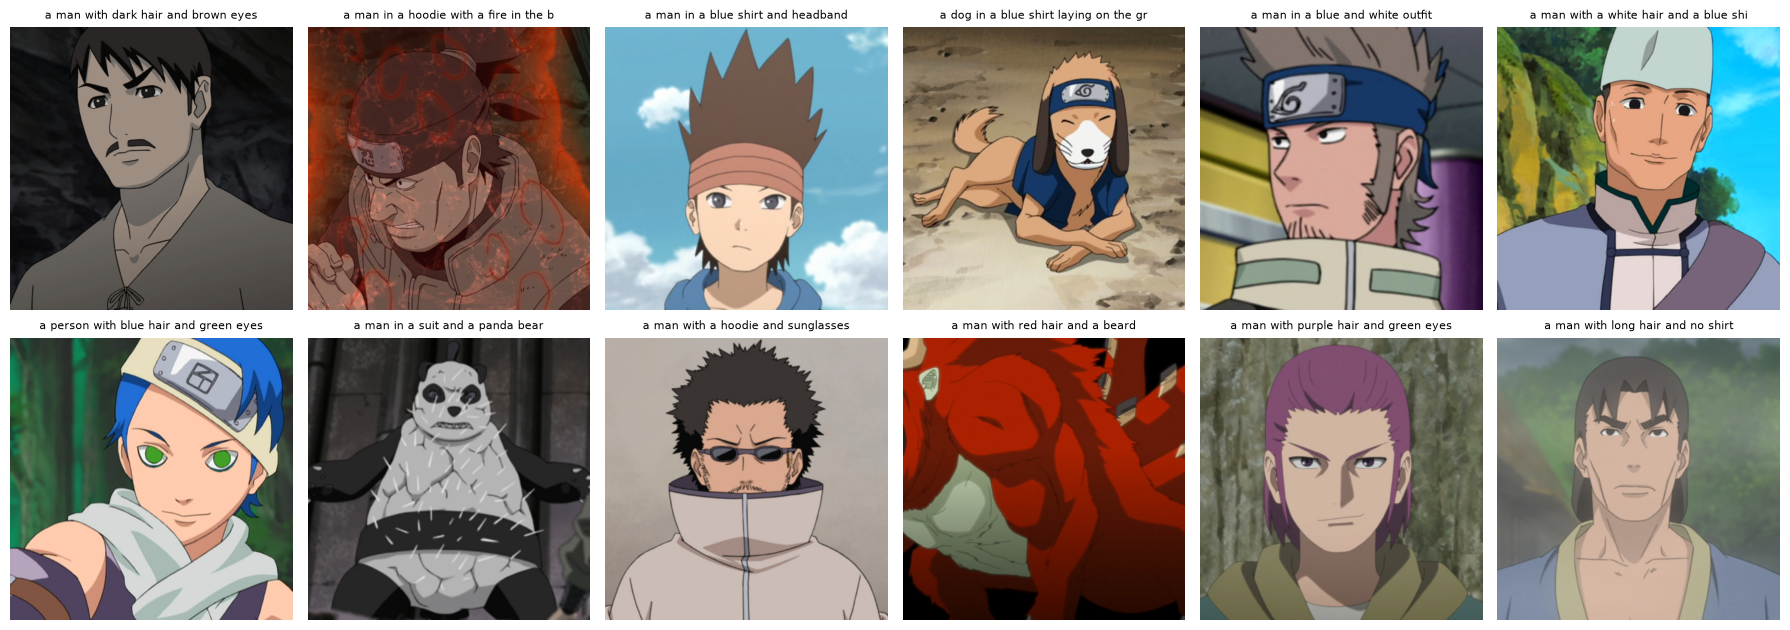

In [13]:
t0 = time.time()
prep = D.prepare(cfg)
rep = prep["report"]
print("cleaning report:", rep.summary())
print("removed as corrupted / unusable:", rep.corrupted)
print("exact duplicates:", rep.exact_duplicates, "| near duplicates:", rep.near_duplicates)
TRAIN, TEST = D.load_split(cfg, "train"), D.load_split(cfg, "test")
print(f"train={len(TRAIN)} test={len(TEST)}  ({time.time() - t0:.0f}s)")
print("train captions:", D.describe(TRAIN))
print("test captions:", D.describe(TEST))
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for ax, r in zip(axes.flat, TRAIN[:12]):
    ax.imshow(Image.open(r["path"])); ax.set_title(r["text"][:38], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

**Dataset description.** Frames of Naruto characters from Narutopedia, each with one short BLIP caption
(statistics above). *Limitations / biases* (check them against the statistics and examples above and edit in your own words):
1. The captions are short and generic (BLIP, mostly "a man with ..."), so they describe hair colour and clothing but not
   the art style, names or actions; many captions repeat or contain BLIP artefacts ("a hoodie and a hoodie").
2. The images are skewed towards a few main (mostly male) characters and close-up portraits, so the model will be
   better at faces than at scenes, landscapes or objects; it also inherits the franchise's copyrighted designs.

## 2. Fine-tuning (Task 2.2): two runs, same data / steps / batch size / learning rate

[train run1_lora_r4] loaded existing adapter and its measured statistics from .\artifacts_p2\lora\run1_lora_r4\train_stats.json
[train run2_lora_r32] loaded existing adapter and its measured statistics from .\artifacts_p2\lora\run2_lora_r32\train_stats.json


,run,method,trainable_params,learning_rate,steps,batch_size,epochs,resolution,peak_gpu_memory_gb,train_time_s,gpu_hours,final_loss_avg100,device
0,run1_lora_r4,LoRA rank 4 (alpha 4) on UNet attention,797184,0.0001,1500,4,5.46,512,3.80,520.9,0.145,0.0634,NVIDIA GeForce RTX 4090
1,run2_lora_r32,LoRA rank 32 (alpha 32) on UNet attention,6377472,0.0001,1500,4,5.46,512,3.86,521.9,0.145,0.0632,NVIDIA GeForce RTX 4090


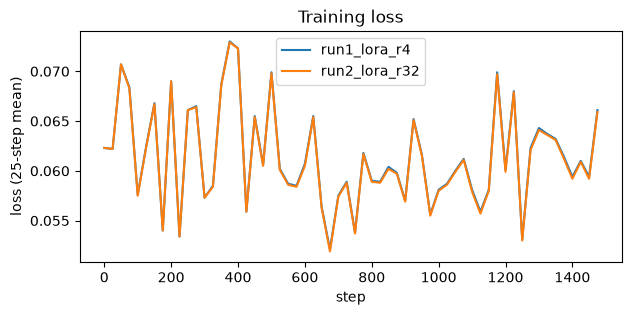

In [14]:
STATS = {}
for name, rank in cfg.runs:
    f = os.path.join(cfg.work_dir, "lora", name, "train_stats.json")
    if os.path.isfile(f) and os.environ.get("P2_RETRAIN", "0") != "1":
        STATS[name] = json.load(open(f))  # a previous run of this notebook trained it (set P2_RETRAIN=1 to train again)
        print(f"[train {name}] loaded existing adapter and its measured statistics from {f}")
    else:
        STATS[name] = T.train_lora(cfg, name, rank, TRAIN)
cols = ["run", "method", "trainable_params", "learning_rate", "steps", "batch_size", "epochs", "resolution",
        "peak_gpu_memory_gb", "train_time_s", "gpu_hours", "final_loss_avg100", "device"]
train_table = pd.DataFrame([{c: s[c] for c in cols} for s in STATS.values()])
display(train_table)
plt.figure(figsize=(7, 3))
for n, s in STATS.items():
    plt.plot([25 * i for i in range(len(s["loss_curve"]))], s["loss_curve"], label=n)
plt.xlabel("step"); plt.ylabel("loss (25-step mean)"); plt.legend(); plt.title("Training loss"); plt.show()

## 3. Image generation (Task 2.3): 20 fixed prompts x seeds 0 and 1, base model and both runs

W1116 15:23:30.739000 36068 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:  50%|█████     | 100/200 [00:00<00:00, 963.26it/s]

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 1627.75it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:  23%|██▎       | 92/396 [00:00<00:00, 919.05it/s]

... (47 outputs left out)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


[generate] run2_lora_r32: 40 images in 49s (1.2 s/image); filtered by the NSFW classifier: 0, SD safety checker would flag: 11
120 images in 146 s; {'base': 40, 'run1_lora_r4': 40, 'run2_lora_r32': 40}


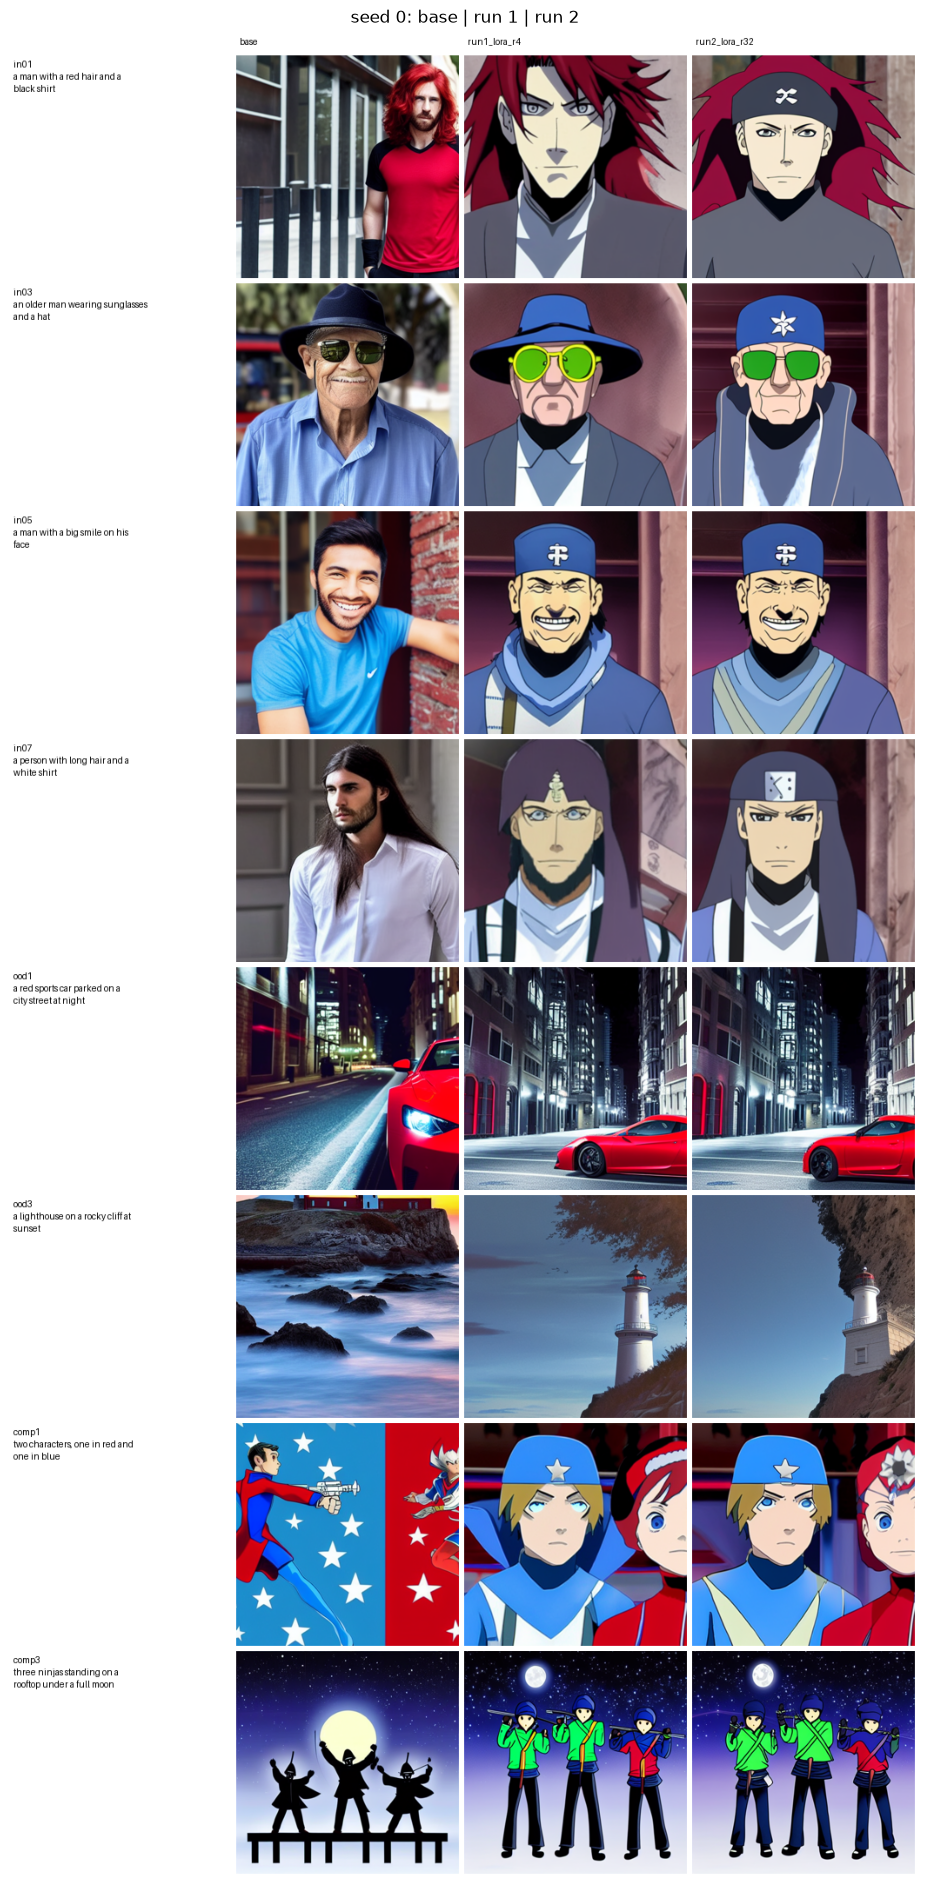

In [15]:
models = {"base": None, **{n: s["lora_dir"] for n, s in STATS.items()}}
t0 = time.time()
ROWS = G.generate_all(cfg, PROMPTS["prompts"], models, os.path.join(cfg.work_dir, "generated"))
print(len(ROWS), "images in", round(time.time() - t0), "s;", pd.DataFrame(ROWS).groupby("model").size().to_dict())
grid_path = E.grid(ROWS, PROMPTS["grid_prompts"], list(models), os.path.join(OUT, "p2_grid.png"), seed=0)
plt.figure(figsize=(14, 24)); plt.imshow(Image.open(grid_path)); plt.axis("off"); plt.title("seed 0: base | run 1 | run 2"); plt.show()

## 4. Evaluation (Task 2.4): KID, CLIP score, LPIPS diversity

In [16]:
clip = E.Clip()
for r, s in zip(ROWS, clip.score([r["path"] for r in ROWS], [r["prompt"] for r in ROWS])):
    r["clip_score"] = s
LP = E.lpips_pairs(ROWS)
TEST_PATHS = [r["path"] for r in TEST]
SUMMARY = E.summary_table(ROWS, TEST_PATHS, STATS, LP)
display(SUMMARY)
display(pd.DataFrame(ROWS).groupby(["model", "kind"]).clip_score.mean().unstack().round(2))
display(LP.groupby(["model", "kind"]).lpips.mean().unstack().round(3))
# suggested final run: lowest in-domain KID, ties broken by in-domain CLIP (the team makes the final choice)
fine = SUMMARY[SUMMARY.model != "base"].copy()
fine["kid"] = fine["KID in-domain (x1e3, lower=better)"].str.split(" ").str[0].astype(float)
FINAL = os.environ.get("P2_FINAL") or fine.sort_values(["kid", "CLIP in-domain"], ascending=[True, False]).iloc[0]["model"]
print("final run:", FINAL)

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights:  14%|█▎        | 80/590 [00:00<00:00, 782.58it/s]

Loading weights:  27%|██▋       | 159/590 [00:00<00:00, 651.48it/s]

Loading weights:  38%|███▊      | 226/590 [00:00<00:00, 554.05it/s]

Loading weights:  48%|████▊     | 284/590 [00:00<00:00, 419.57it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 858.31it/s]

... (4 outputs left out)

,model,"KID in-domain (x1e3, lower=better)",CLIP score all,CLIP in-domain,CLIP out-of-domain,CLIP compositional,LPIPS diversity,images used / 40,NSFW filtered (classifier),SD checker would flag,GPU-hours (training),peak GPU memory GB (training)
0,base,132.50 +- 10.09,26.12,25.19,25.74,28.37,0.689,40/40,0,1,-,-
1,run1_lora_r4,10.47 +- 4.23,24.58,23.53,25.01,26.26,0.684,40/40,0,9,0.145,3.8
2,run2_lora_r32,18.17 +- 5.67,24.75,23.19,25.10,27.51,0.682,40/40,0,11,0.145,3.86


kind,compositional,in_domain,out_of_domain
model,,,
base,28.37,25.19,25.74
run1_lora_r4,26.26,23.53,25.01
run2_lora_r32,27.51,23.19,25.10


kind,compositional,in_domain,out_of_domain
model,,,
base,0.717,0.673,0.693
run1_lora_r4,0.728,0.655,0.700
run2_lora_r32,0.696,0.651,0.731


final run: run1_lora_r4


## 5. Human evaluation
25 blinded pairs (final run vs base model, left/right randomised with seed 266). Three raters (both members + one outside person) each write A or B for *domain style* and for *prompt match* in `p2_human_eval.csv`, without opening the KEY file. Re-run this cell once the sheet is filled in.

In [17]:
HUMAN_DIR = os.path.join(OUT, "p2_human_eval")
filled = next((p for p in ["../part2/eval/p2_human_eval.csv", "part2/eval/p2_human_eval.csv"] if os.path.isfile(p)), "")
sheet, key = E.human_eval_sheets(ROWS, FINAL, "base", HUMAN_DIR)
if filled:
    sheet = filled
HUMAN = E.human_eval_stats(sheet, key)
print("sheet:", sheet, "| key:", key)
print(HUMAN or "not rated yet: fill rater1/2/3 columns with A or B and re-run")

sheet: .\p2_human_eval\p2_human_eval.csv | key: .\p2_human_eval\p2_human_eval_KEY.csv
{'win_rate_style': 0.4, 'votes_style': 75, 'per_rater_style': {'rater1': '10/25', 'rater2': '8/25', 'rater3': '12/25'}, 'win_rate_prompt': 0.507, 'votes_prompt': 75, 'per_rater_prompt': {'rater1': '14/25', 'rater2': '14/25', 'rater3': '10/25'}}


## 6. Failure modes
Candidates found automatically: the final run's lowest CLIP scores (prompt ignored) and its most similar seed pairs (repeated outputs). Describe at least two failure modes in your own words.

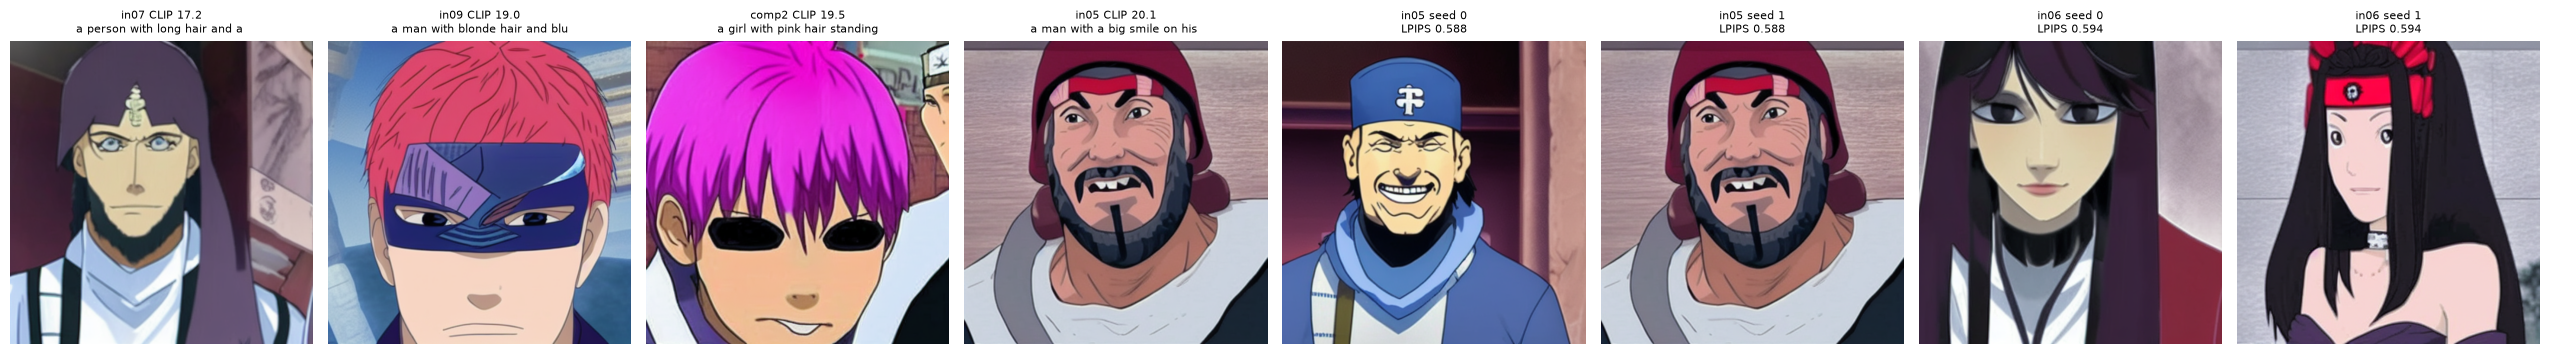

In [18]:
df = pd.DataFrame(ROWS)
worst = df[(df.model == FINAL) & ~df.nsfw_filtered].sort_values("clip_score").head(4)
same = LP[LP.model == FINAL].sort_values("lpips").head(2)
show = list(worst.itertuples())
fig, axes = plt.subplots(1, len(show) + 2 * len(same), figsize=(3.2 * (len(show) + 2 * len(same)), 3.6))
k = 0
for r in show:
    axes[k].imshow(Image.open(r.path)); axes[k].set_title(f"{r.prompt_id} CLIP {r.clip_score:.1f}\n{r.prompt[:30]}", fontsize=8); k += 1
for r in same.itertuples():
    for s in (0, 1):
        p = df[(df.model == FINAL) & (df.prompt_id == r.prompt_id) & (df.seed == s)].path.iloc[0]
        axes[k].imshow(Image.open(p)); axes[k].set_title(f"{r.prompt_id} seed {s}\nLPIPS {r.lpips:.3f}", fontsize=8); k += 1
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Safety (C4): license, NSFW filter, memorization check
**License:** Naruto characters are copyrighted; the dataset card states no license, so the model is for non-commercial research only. SD 1.5 is CreativeML OpenRAIL-M. **NSFW filter:** every generated image is screened by an NSFW image classifier (`Falconsai/nsfw_image_detection`); filtered images are blurred and excluded from all metrics. The Stable Diffusion safety checker's flags are recorded for comparison (on our first run it blacked out many harmless anime portraits); review its extra flags below. **Memorization:** for 10 in-domain images of the final run, the most similar training image by CLIP image embedding; the 3 closest pairs are shown.

NSFW classifier - filtered images per model: {'base': 0, 'run1_lora_r4': 0, 'run2_lora_r32': 0}
SD safety checker - would flag per model:    {'base': 1, 'run1_lora_r4': 9, 'run2_lora_r32': 11}
21 images flagged by the SD checker but not by the classifier - review them below (false positives?)


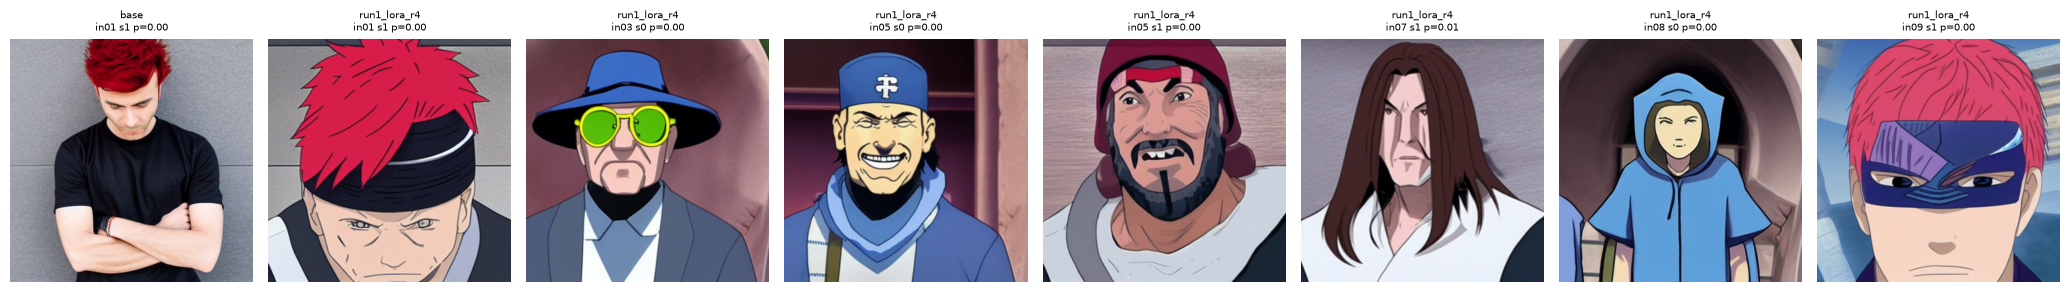

,generated,nearest_train,cosine
0,run1_lora_r4__in01__s0.png,00649.png,0.831170
1,run1_lora_r4__in02__s0.png,00656.png,0.602434
2,run1_lora_r4__in03__s0.png,00989.png,0.831854
3,run1_lora_r4__in04__s0.png,00676.png,0.838396
4,run1_lora_r4__in05__s0.png,01040.png,0.892625
5,run1_lora_r4__in06__s0.png,00125.png,0.841111
6,run1_lora_r4__in07__s0.png,00807.png,0.873828
7,run1_lora_r4__in08__s0.png,00526.png,0.848511
8,run1_lora_r4__in09__s0.png,00146.png,0.814215
9,run1_lora_r4__in10__s0.png,00592.png,0.692107


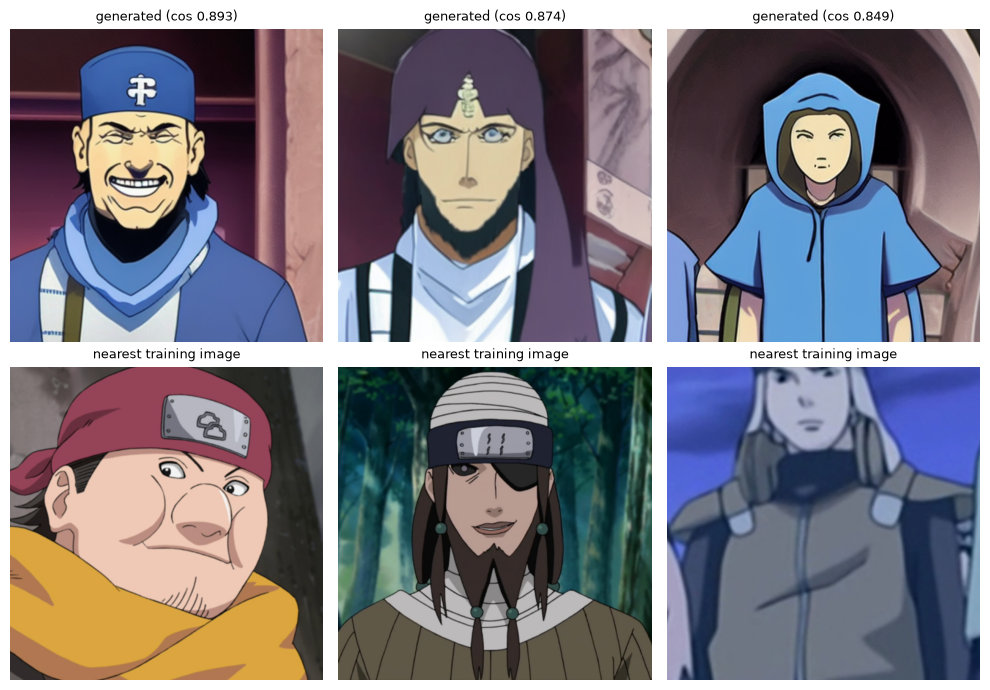

In [19]:
print("NSFW classifier - filtered images per model:", df.groupby("model").nsfw_filtered.sum().to_dict())
print("SD safety checker - would flag per model:   ", df.groupby("model").sd_checker_flag.apply(lambda x: int(x.fillna(False).astype(bool).sum())).to_dict())
sd_only = df[df.sd_checker_flag.fillna(False).astype(bool) & ~df.nsfw_filtered]
print(len(sd_only), "images flagged by the SD checker but not by the classifier - review them below (false positives?)")
if len(sd_only):
    k = min(8, len(sd_only))
    fig, axes = plt.subplots(1, k, figsize=(2.6 * k, 3))
    for ax, r in zip(np.atleast_1d(axes), sd_only.head(k).itertuples()):
        ax.imshow(Image.open(r.path)); ax.set_title(f"{r.model}\n{r.prompt_id} s{r.seed} p={r.nsfw_prob:.2f}", fontsize=7); ax.axis("off")
    plt.tight_layout(); plt.show()
ok = df[~df.nsfw_filtered]
mem_gen = list(ok[(ok.model == FINAL) & (ok.kind == "in_domain")].sort_values(["seed", "prompt_id"]).path)[:10]
TOP3, MEM = E.memorization(clip, mem_gen, [r["path"] for r in TRAIN], k=3)
display(pd.DataFrame(MEM)[["generated", "nearest_train", "cosine"]].assign(
    generated=lambda d: d.generated.map(os.path.basename), nearest_train=lambda d: d.nearest_train.map(os.path.basename)))
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for j, m in enumerate(TOP3):
    axes[0, j].imshow(Image.open(m["generated"])); axes[0, j].set_title(f"generated (cos {m['cosine']:.3f})", fontsize=9)
    axes[1, j].imshow(Image.open(m["nearest_train"])); axes[1, j].set_title("nearest training image", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Upload to Hugging Face (both adapters + model card for the final run; all generated images)
Needs `huggingface-cli login` (or the HF_TOKEN variable / Kaggle secret). Without it this cell only prints what it would push; Part 3 can also load the adapter from the local folder.

In [20]:
def results_md(name):
    r = SUMMARY.set_index("model")
    keep = ["KID in-domain (x1e3, lower=better)", "CLIP score all", "CLIP in-domain", "CLIP out-of-domain", "LPIPS diversity"]
    return r.loc[["base", name], keep].to_markdown()
data_info = {"train": len(TRAIN), "test": len(TEST), "removed": rep.summary()["total"] - rep.summary()["kept"]}
REPOS = {}
for name, s in STATS.items():
    REPOS[name] = H.push_lora(cfg, s, results_md(name), data_info)
IMAGES_REPO = H.push_images(cfg, ROWS)
print("models:", REPOS, "| images:", IMAGES_REPO)
print("local adapter for Part 3 (LORA_REPO):", os.path.abspath(STATS[FINAL]["lora_dir"]))

No files have been modified since last commit. Skipping to prevent empty commit.


[hub] pushed Shibin22/sd15-naruto-run1-lora-r4


No files have been modified since last commit. Skipping to prevent empty commit.


Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


[hub] pushed Shibin22/sd15-naruto-run2-lora-r32


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

... (16 outputs left out)


Uploading the dataset shards: 100%|██████████| 1/1 [00:00<00:00,  1.06 shards/s]

Uploading the dataset shards: 100%|██████████| 1/1 [00:00<00:00,  1.06 shards/s]

No files have been modified since last commit. Skipping to prevent empty commit.


[hub] pushed 120 images to datasets/Shibin22/lab2-p2-generated-images
models: {'run1_lora_r4': 'Shibin22/sd15-naruto-run1-lora-r4', 'run2_lora_r32': 'Shibin22/sd15-naruto-run2-lora-r32'} | images: Shibin22/lab2-p2-generated-images
local adapter for Part 3 (LORA_REPO): C:\Users\shibin\data266-lab2\notebooks\artifacts_p2\lora\run1_lora_r4


## 9. Results table (C2): base model (baseline) vs fine-tuned runs

In [21]:
table = SUMMARY.copy()
if HUMAN:
    table["human win rate vs base (style / prompt)"] = [
        "-" if m != FINAL else f"{HUMAN.get('win_rate_style', '-')} / {HUMAN.get('win_rate_prompt', '-')}" for m in table.model]
display(table)
table.to_csv(os.path.join(OUT, "p2_results_table.csv"), index=False)
train_table.to_csv(os.path.join(OUT, "p2_training_table.csv"), index=False)
pd.DataFrame(ROWS).to_csv(os.path.join(OUT, "p2_generated.csv"), index=False)
json.dump({"final_run": FINAL, "summary": SUMMARY.to_dict(orient="records"), "training": train_table.to_dict(orient="records"),
           "human": HUMAN, "memorization_top3": TOP3, "repos": REPOS, "images_repo": IMAGES_REPO,
           "local_final_adapter": os.path.abspath(STATS[FINAL]["lora_dir"])},
          open(os.path.join(OUT, "p2_results.json"), "w", encoding="utf-8"), indent=1, default=str)
print("saved p2_results_table.csv, p2_training_table.csv, p2_generated.csv, p2_results.json")

,model,"KID in-domain (x1e3, lower=better)",CLIP score all,CLIP in-domain,CLIP out-of-domain,CLIP compositional,LPIPS diversity,images used / 40,NSFW filtered (classifier),SD checker would flag,GPU-hours (training),peak GPU memory GB (training),human win rate vs base (style / prompt)
0,base,132.50 +- 10.09,26.12,25.19,25.74,28.37,0.689,40/40,0,1,-,-,-
1,run1_lora_r4,10.47 +- 4.23,24.58,23.53,25.01,26.26,0.684,40/40,0,9,0.145,3.8,0.4 / 0.507
2,run2_lora_r32,18.17 +- 5.67,24.75,23.19,25.10,27.51,0.682,40/40,0,11,0.145,3.86,-


saved p2_results_table.csv, p2_training_table.csv, p2_generated.csv, p2_results.json
